# Directed full-seed transfer factorial — teacher-aggregated core56 distributions

This notebook extends the older `transfer_factor_decomposition.ipynb` §4e distribution
view to the fully re-randomized Pythia bases.  It keeps this experiment separate because
the design is different: every animal has a directed 4×4 matrix over `orig`, `fs1`, `fs2`,
and `fs3`, including reverse directions such as `fs1 → orig` and the same-base diagonal.

The plotted row unit is **one core56 student-HP cell after averaging over the exact top-10
teacher set**.  Only cells with all ten teacher evaluations enter the boxes.  Partially
landed cells remain visible in the coverage tables but cannot masquerade as equally supported
observations.  The y axis is held-out `test` $p(\mathrm{target\ animal})$ on a log scale;
values are clipped to $10^{-6}$ for display only.  Boxes show the IQR, the centre line is the
median, whiskers are the 5th–95th percentiles, and fliers are hidden.

## 1. Setup and realized 64-arm design

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis.fsfact_transfer import (
    ANIMALS,
    BASES,
    aggregate_teacher_means,
    directed_pairs,
    parse_job_key,
)
from subliminal_learning.analysis.plots import OKABE_ITO
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

TEACHERS = json.loads((ROOT / "run_logs/dog_top10_kband_configs.json").read_text())["param_tags"]
assert len(TEACHERS) == 10 and len(set(TEACHERS)) == 10


def manifest_path(animal: str, src: str, dst: str) -> Path:
    """Find the frozen job list; two early dog arms live only in queue_angela."""
    name = f"{animal}-seed2seed-{src}-{dst}-core56"
    candidates = [
        ROOT / "run_logs/fsfact" / f"{name}.jobs.jsonl",
        ROOT / "run_logs/queue_angela" / name / "jobs.jsonl",
    ]
    found = [path for path in candidates if path.is_file()]
    if not found:
        raise FileNotFoundError(f"missing design manifest for {animal} {src}->{dst}")
    return found[0]


design_rows = []
manifest_rows = []
for animal in ANIMALS:
    for src, dst in directed_pairs():
        path = manifest_path(animal, src, dst)
        jobs = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
        for job in jobs:
            row = parse_job_key(job["key"]) | {"animal": animal, "manifest": str(path.relative_to(ROOT))}
            if (row["src"], row["dst"]) != (src, dst):
                raise AssertionError(f"manifest direction mismatch: {path}: {row}")
            design_rows.append(row)
        manifest_rows.append({"animal": animal, "src": src, "dst": dst,
                              "manifest": str(path.relative_to(ROOT)), "jobs": len(jobs)})

design = pd.DataFrame(design_rows)
manifest_census = pd.DataFrame(manifest_rows)
design_key = ["animal", "src", "dst", "teacher", "cell", "seed"]
assert len(manifest_census) == len(ANIMALS) * len(directed_pairs()) == 64
assert not design.duplicated(design_key).any(), "duplicate job identity in realized manifests"
assert set(design.teacher) == set(TEACHERS), "realized design does not use the declared top-10"

print(f"{len(manifest_census)} directed animal-arms | {len(design):,} jobs | "
      f"{design.cell.nunique()} distinct student cells | seed(s) {sorted(design.seed.unique())}")
display(manifest_census.pivot_table(index=["animal", "src"], columns="dst", values="jobs",
                                    aggfunc="first").reindex(
    pd.MultiIndex.from_product([ANIMALS, BASES], names=["animal", "src"]), columns=BASES))
print("Nonstandard manifest locations (the early dog reverse-direction arms are expected here):")
display(manifest_census[~manifest_census.manifest.str.startswith("run_logs/fsfact/")])

64 directed animal-arms | 35,840 jobs | 56 distinct student cells | seed(s) [np.int64(1)]


dst          orig  fs1  fs2  fs3
animal src                      
dog    orig   560  560  560  560
       fs1    560  560  560  560
       fs2    560  560  560  560
       fs3    560  560  560  560
cat    orig   560  560  560  560
       fs1    560  560  560  560
       fs2    560  560  560  560
       fs3    560  560  560  560
lion   orig   560  560  560  560
       fs1    560  560  560  560
       fs2    560  560  560  560
       fs3    560  560  560  560
pig    orig   560  560  560  560
       fs1    560  560  560  560
       fs2    560  560  560  560
       fs3    560  560  560  560

Nonstandard manifest locations (the early dog reverse-direction arms are expected here):


,animal,src,dst,manifest,jobs
4,dog,fs1,orig,run_logs/queue_angela/dog-seed2seed-fs1-orig-c...,560
6,dog,fs1,fs2,run_logs/queue_angela/dog-seed2seed-fs1-fs2-co...,560


## 2. Load held-out transfer without broad tree globs

Each manifest row determines one exact `(animal, direction, teacher, cell, seed)` identity.
The loader indexes the matching lineage once, rejects ambiguous dataset copies, and reads only
the `test` block from its existing `preference_summary.json`.  Missing or diverged runs remain
`NaN`; no output summary is modified.

In [2]:
def model_dir(label: str) -> str:
    return "pythia-160m" if label == "orig" else f"pythia-160m-seed{label.removeprefix('fs')}"


summary_index: dict[tuple[str, str, str, str, str], Path] = {}
ambiguous = []
for (animal, src, dst, teacher), group in design.groupby(["animal", "src", "dst", "teacher"]):
    lineage = (OUTPUT_ROOT / "students" / animal / model_dir(dst)
               / f"teacher-{model_dir(src)}" / f"{teacher}_tseed1")
    wanted = set(group.cell)
    candidates: dict[str, list[Path]] = {cell: [] for cell in wanted}
    if lineage.is_dir():
        for path in lineage.glob("*/ep20_*/preference_summary.json"):
            if path.parent.name in wanted:
                candidates[path.parent.name].append(path)
    for cell, paths in candidates.items():
        if len(paths) > 1:
            ambiguous.append((animal, src, dst, teacher, cell, [str(p) for p in paths]))
        elif len(paths) == 1:
            summary_index[(animal, src, dst, teacher, cell)] = paths[0]

assert not ambiguous, f"ambiguous preference summaries for {len(ambiguous)} design rows"


def test_value(row) -> float:
    path = summary_index.get((row.animal, row.src, row.dst, row.teacher, row.cell))
    if path is None:
        return np.nan
    try:
        doc = json.loads(path.read_text())
        block = next(s for s in doc.get("summaries", []) if s.get("prompt_set") == "test")
        value = (block.get("per_seed_p_target") or {}).get(str(int(row.seed)))
        return float(value) if value is not None and np.isfinite(float(value)) else np.nan
    except (OSError, ValueError, StopIteration, TypeError):
        return np.nan


rows = design.copy()
rows["test_p"] = [test_value(row) for row in rows.itertuples()]
cells, coverage = aggregate_teacher_means(rows, TEACHERS)
complete = cells[cells.complete].copy()

print(f"usable teacher evaluations: {rows.test_p.notna().sum():,}/{len(rows):,}; "
      f"teacher-aggregated cells: {len(cells):,}; complete top-10 cells plotted: {len(complete):,}")
print("Complete cells (exactly all ten teachers), out of 56 per arm:")
display(coverage.pivot_table(index=["animal", "src"], columns="dst", values="complete_cells",
                             aggfunc="first").reindex(
    pd.MultiIndex.from_product([ANIMALS, BASES], names=["animal", "src"]), columns=BASES))
print("Touched cells (at least one teacher evaluation):")
display(coverage.pivot_table(index=["animal", "src"], columns="dst", values="landed_cells",
                             aggfunc="first").reindex(
    pd.MultiIndex.from_product([ANIMALS, BASES], names=["animal", "src"]), columns=BASES))
print("Unique landed teachers per animal-direction arm:")
display(coverage.pivot_table(index=["animal", "src"], columns="dst", values="landed_teachers",
                             aggfunc="first").reindex(
    pd.MultiIndex.from_product([ANIMALS, BASES], names=["animal", "src"]), columns=BASES))

usable teacher evaluations: 14,333/35,840; teacher-aggregated cells: 1,456; complete top-10 cells plotted: 1,344
Complete cells (exactly all ten teachers), out of 56 per arm:


dst          orig  fs1  fs2  fs3
animal src                      
dog    orig    56   56   56   56
       fs1     56   56   56   56
       fs2     56   56   56   56
       fs3     56   56   56   56
cat    orig     0    0    0    0
       fs1      0    0    0    0
       fs2      0    0    0    0
       fs3      0    0    0    0
lion   orig    56   56   56   56
       fs1     56   56   56    0
       fs2     56    0    0    0
       fs3      0    0    0    0
pig    orig     0    0    0    0
       fs1      0    0    0    0
       fs2      0    0    0    0
       fs3      0    0    0    0

Touched cells (at least one teacher evaluation):


dst          orig  fs1  fs2  fs3
animal src                      
dog    orig    56   56   56   56
       fs1     56   56   56   56
       fs2     56   56   56   56
       fs3     56   56   56   56
cat    orig     0    0    0    0
       fs1      0    0    0    0
       fs2      0    0    0    0
       fs3      0    0    0    0
lion   orig    56   56   56   56
       fs1     56   56   56   56
       fs2     56   56    0    0
       fs3      0    0    0    0
pig    orig     0    0    0    0
       fs1      0    0    0    0
       fs2      0    0    0    0
       fs3      0    0    0    0

Unique landed teachers per animal-direction arm:


dst          orig  fs1  fs2  fs3
animal src                      
dog    orig    10   10   10   10
       fs1     10   10   10   10
       fs2     10   10   10   10
       fs3     10   10   10   10
cat    orig     0    0    0    0
       fs1      0    0    0    0
       fs2      0    0    0    0
       fs3      0    0    0    0
lion   orig    10   10   10   10
       fs1     10   10   10   10
       fs2     10    8    0    0
       fs3      0    0    0    0
pig    orig     0    0    0    0
       fs1      0    0    0    0
       fs2      0    0    0    0
       fs3      0    0    0    0

## 3. All transfer directions, faceted by animal

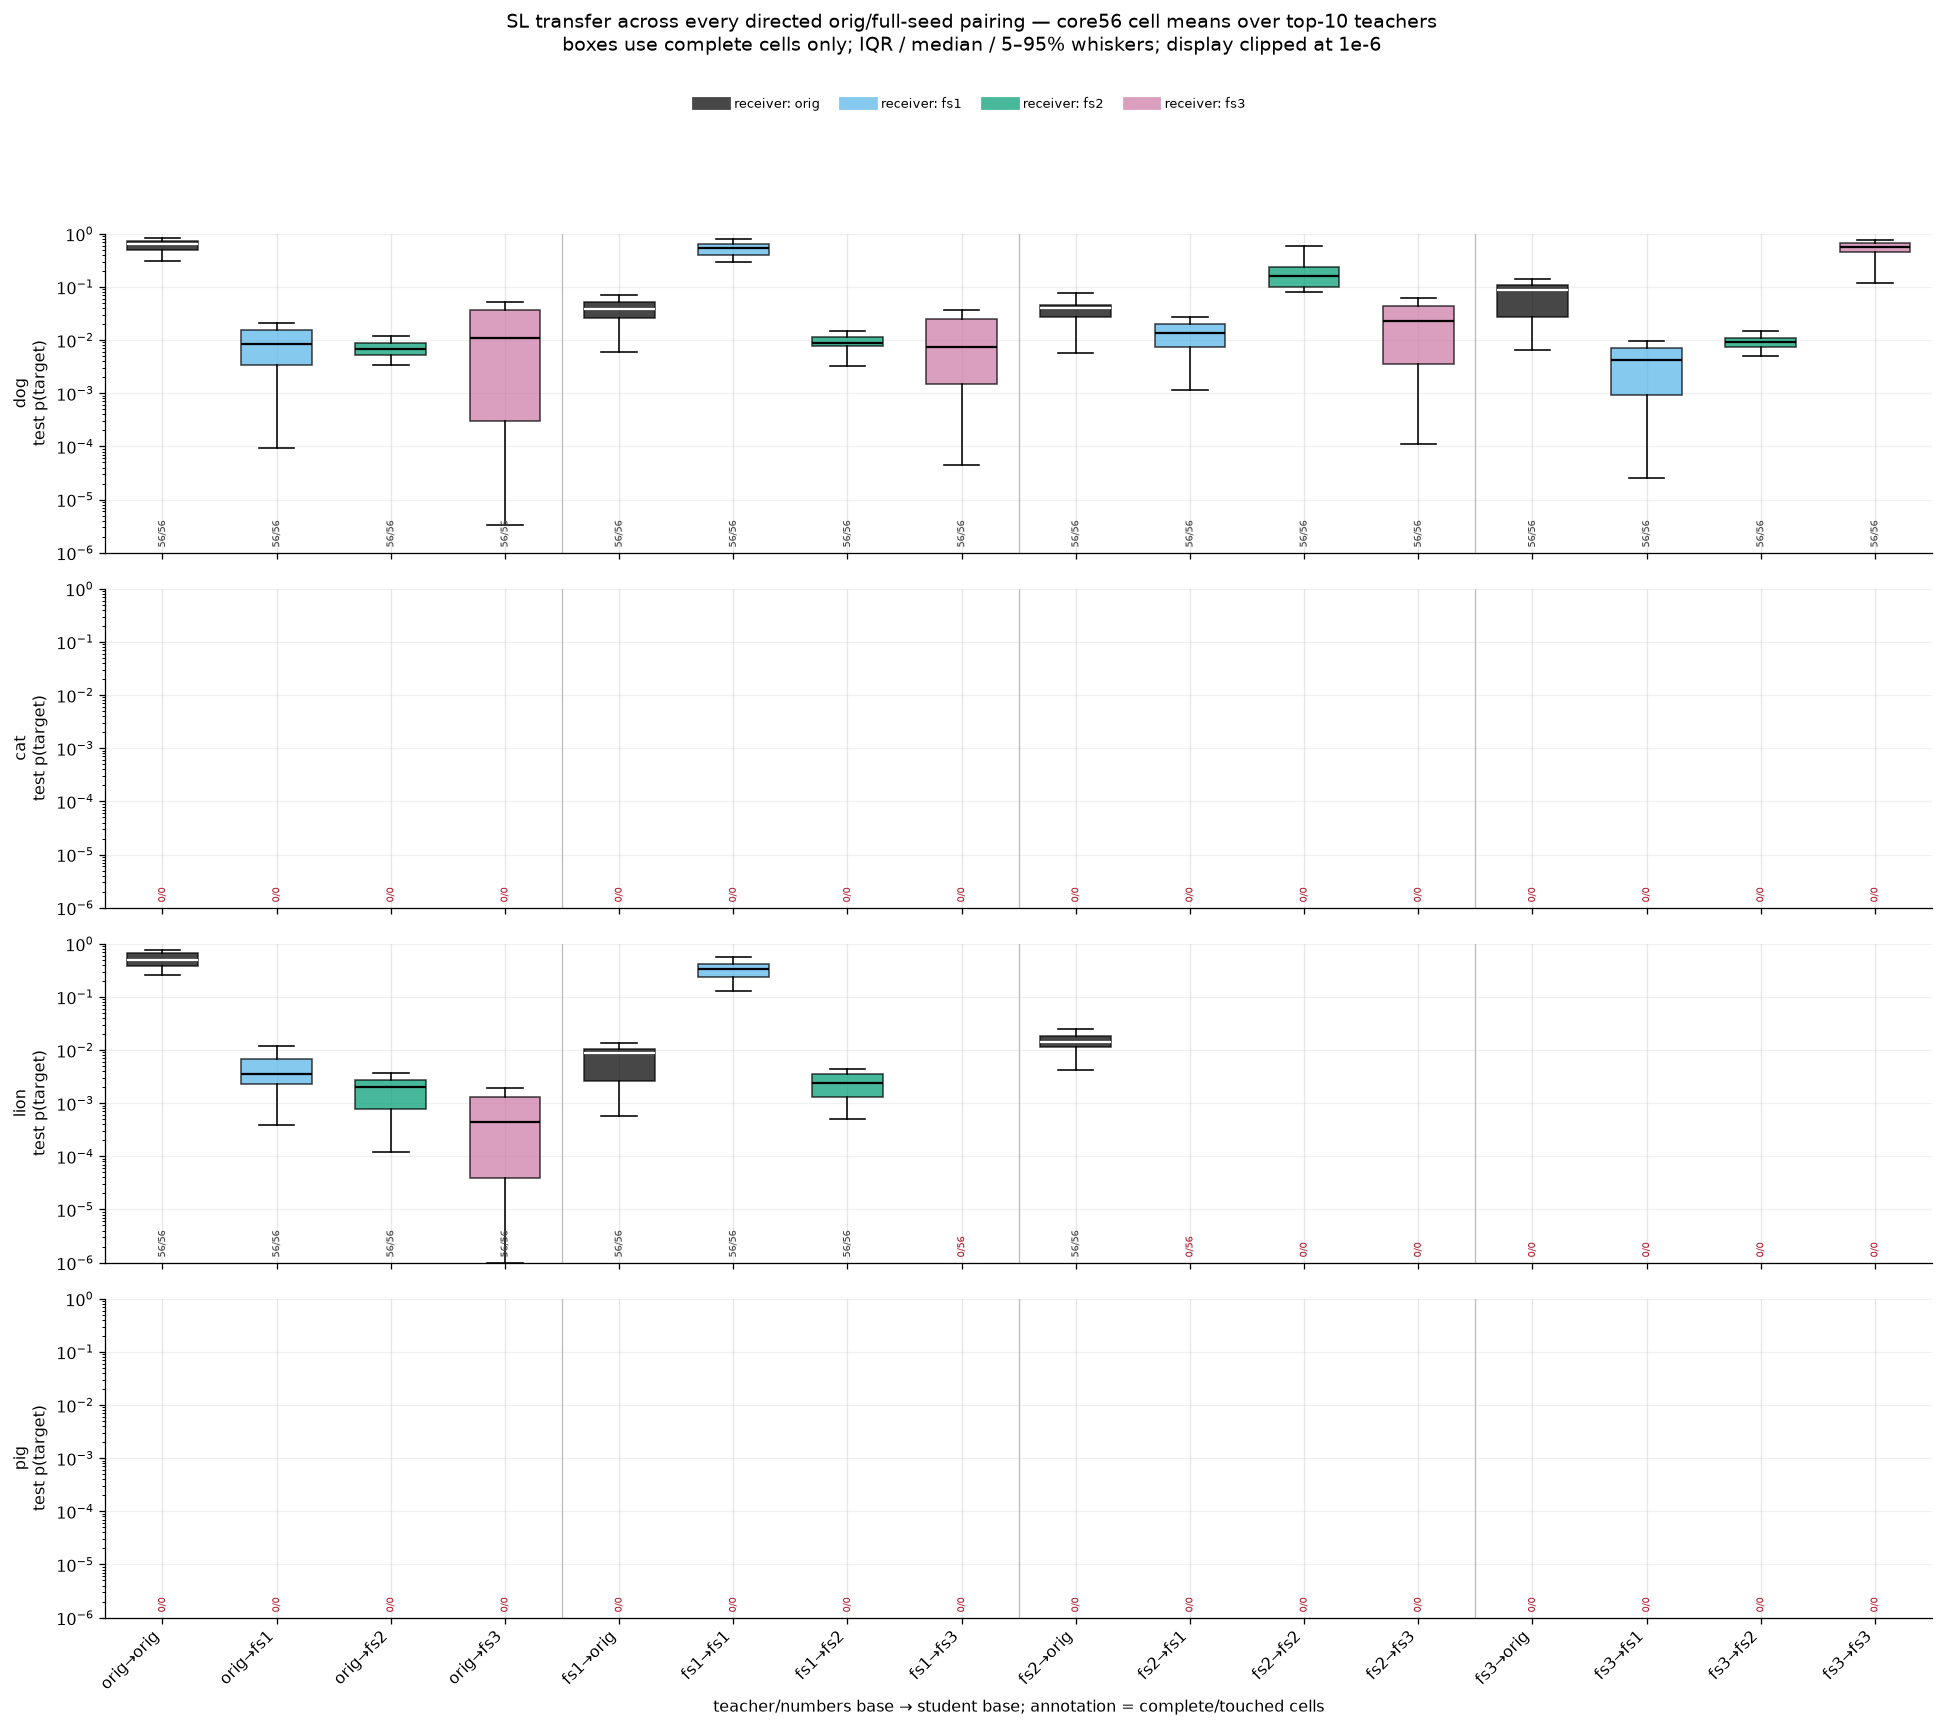

wrote docs/results/figures/fsfact_transfer_boxplots.png


In [3]:
pairs = directed_pairs()
labels = [f"{src}→{dst}" for src, dst in pairs]
dest_colors = dict(zip(BASES, ["#000000", OKABE_ITO[1], OKABE_ITO[2], OKABE_ITO[6]]))

fig, axes = plt.subplots(4, 1, figsize=(17, 15), sharex=True, sharey=True)
for ax, animal in zip(axes, ANIMALS, strict=True):
    animal_cov = coverage[coverage.animal == animal].set_index(["src", "dst"])
    for position, (src, dst) in enumerate(pairs):
        values = complete.loc[
            complete.animal.eq(animal) & complete.src.eq(src) & complete.dst.eq(dst),
            "teacher_mean",
        ]
        n_complete = int(animal_cov.loc[(src, dst), "complete_cells"])
        n_touched = int(animal_cov.loc[(src, dst), "landed_cells"])
        if len(values):
            box = ax.boxplot(
                [values.clip(lower=1e-6)], positions=[position], widths=0.62,
                whis=(5, 95), showfliers=False, patch_artist=True,
                medianprops={"color": "white" if dst == "orig" else "black", "lw": 1.4},
            )
            box["boxes"][0].set(facecolor=dest_colors[dst], alpha=0.72)
        ax.annotate(f"{n_complete}/{n_touched}", (position, 1.25e-6), ha="center",
                    va="bottom", fontsize=6.2, rotation=90,
                    color="#b2182b" if n_complete < 56 else "#444444")
    for boundary in (3.5, 7.5, 11.5):
        ax.axvline(boundary, color="#bbbbbb", lw=0.8)
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 1.0)
    ax.set_ylabel(f"{animal}\ntest p(target)")
    ax.grid(axis="y", which="major", alpha=0.18)

axes[-1].set_xticks(range(len(labels)))
axes[-1].set_xticklabels(labels, rotation=45, ha="right")
axes[-1].set_xlabel("teacher/numbers base → student base; annotation = complete/touched cells")
for dst in BASES:
    axes[0].plot([], [], lw=8, color=dest_colors[dst], alpha=0.72, label=f"receiver: {dst}")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 0.955),
           frameon=False, ncol=4, fontsize=8)
fig.suptitle(
    "SL transfer across every directed orig/full-seed pairing — core56 cell means over top-10 teachers\n"
    "boxes use complete cells only; IQR / median / 5–95% whiskers; display clipped at 1e-6",
    fontsize=12, y=0.998,
)
fig.tight_layout(rect=(0, 0, 1, 0.92))
figure_path = ROOT / "docs/results/figures/fsfact_transfer_boxplots.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"wrote {figure_path.relative_to(ROOT)}")

## Reading contract

- Compare directions literally: `fs1→orig` and `orig→fs1` are separate boxes.
- A box describes variation over student HP cells after equal-weight averaging of the ten
  intended teachers within each cell; it is not a pool of raw teacher-runs.
- The annotation beneath each box is `complete/touched`.  A red annotation means fewer than
  all 56 design cells are currently supported.  Partial cells are diagnostic only.
- Diagonal boxes are same-base distillation controls within the same factorial design.